# Análisis de las 10.000 Empresas más Grandes de Colombia

## Fuente de los datos

**Conjunto de datos:** 10.000 Empresas más Grandes del País

**Fuente:** Portal de Datos Abiertos de Colombia  
**Entidad publicadora:** Superintendencia de Sociedades  
**Sector:** Comercio, Industria y Turismo

**Enlace al conjunto de datos:**  
https://www.datos.gov.co/Comercio-Industria-y-Turismo/10-000-Empresas-mas-Grandes-del-Pa-s/6cat-2gcs/about_data

## Condiciones de uso

Los datos provienen del Portal Nacional de Datos Abiertos de Colombia (datos.gov.co) y pueden ser utilizados, reutilizados y transformados para realizar análisis e investigación, respetando las condiciones de uso del portal.

Para el uso de los datos se debe citar la fuente como:

> Fuente: Portal de Datos Abiertos www.datos.gov.co

También se debe conservar la información relacionada con la fecha de actualización y las condiciones de uso aplicables al conjunto de datos.

## Preguntas de investigación

1. ¿Qué macrosector económico concentra mayores ingresos operacionales?
2. ¿Qué región concentra los mayores ingresos operacionales?
3. ¿Qué macrosectores concentran el mayor número de empresas?
4. ¿Las empresas con más activos también tienen más ingresos operacionales y más patrimonio?

### Carga del dataset
Se cargo el archivo CSV local para que el análisis siempre use los mismos datos, aunque el portal cambie después. Se importo las librerías que voy a usar para tablas (pandas) y gráficos (matplotlib y seaborn).

In [160]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

df = pd.read_csv("10_000_Empresas_mas_Grandes_del_País_20260927.csv")
print(df.shape)
df.head()

(50000, 14)


,NIT,RAZÓN SOCIAL,SUPERVISOR,REGIÓN,DEPARTAMENTO DOMICILIO,CIUDAD DOMICILIO,CIIU,MACROSECTOR,INGRESOS OPERACIONALES,GANANCIA (PÉRDIDA),TOTAL ACTIVOS,TOTAL PASIVOS,TOTAL PATRIMONIO,Año de Corte
0,"899,999,068",ECOPETROL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",610,MINERO,$ 100.59,$ 9.03,$ 198.11,$ 114.35,$ 83.76,"2,025"
1,"830,095,213",ORGANIZACIÓN TERPEL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.","4,661",COMERCIO,$ 26.40,$ 0.63,$ 8.11,$ 4.70,$ 3.41,"2,025"
2,"900,112,515",REFINERIA DE CARTAGENA S.A.,SUPERSERVICIOS,REGIÓN CARIBE,BOLIVAR,CARTAGENA,"1,921",MANUFACTURA,$ 22.40,-$ 0.82,$ 34.95,$ 11.57,$ 23.38,"2,025"
3,"900,276,962",D1 S.A.S.,SUPERSOCIEDADES,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.","4,711",COMERCIO,$ 21.61,$ 0.42,$ 6.94,$ 6.72,$ 0.21,"2,025"
4,"890,904,996",EMPRESAS PÚBLICAS DE MEDELLÍN E.S.P.,SUPERFINANCIERA,ANTIOQUIA,ANTIOQUIA,MEDELLÍN,"3,513",SERVICIOS,$ 20.29,$ 4.88,$ 71.08,$ 36.11,$ 34.97,"2,025"


### Limpieza 1: columna de ingresos
Los ingresos venían como texto con el símbolo `$` y espacios (ejemplo: "$ 100.59"). No se puede sumar ni promediar texto, así que se quito el `$` y los espacios y convierto la columna a número decimal. Sin este paso no se podría responder ninguna pregunta sobre ingresos.

In [161]:
df["INGRESOS OPERACIONALES"] = (
    df["INGRESOS OPERACIONALES"]
    .str.replace("$", "", regex=False)
    .str.replace(" ", "", regex=False)
    .astype(float)
)

df["INGRESOS OPERACIONALES"].describe()

count    50000.000000
mean         0.171192
std          1.365192
min          0.010000
25%          0.030000
50%          0.050000
75%          0.100000
max        144.820000
Name: INGRESOS OPERACIONALES, dtype: float64

### Limpieza 2: NIT, año y duplicados
El NIT y el año venían con comas (ejemplo: "899,999,068" y "2,025"). Al NIT le quito las comas pero lo dejo como texto, porque es solo un código que identifica a la empresa y nunca lo voy a sumar. Al año sí lo convierto a número entero. Después reviso que no haya la misma empresa repetida en el mismo año, porque eso inflaría los ingresos sin razón.

In [162]:
df["NIT"] = df["NIT"].str.replace(",", "", regex=False)
df["Año de Corte"] = df["Año de Corte"].str.replace(",", "", regex=False).astype(int)

duplicados = df.duplicated(subset=["NIT", "Año de Corte"]).sum()
print(f"Filas duplicadas (mismo NIT y mismo año): {duplicados}")

Filas duplicadas (mismo NIT y mismo año): 0


### Pregunta 1: ingresos por macrosector
Agrupo las empresas por macrosector y sumo sus ingresos. Ordeno de mayor a menor para ver de inmediato cuál sector concentra más ingresos.

In [163]:
ingresos_macrosector = df.groupby("MACROSECTOR")["INGRESOS OPERACIONALES"].sum().sort_values(ascending=False)
ingresos_macrosector

MACROSECTOR
COMERCIO        2680.41
SERVICIOS       2434.27
MANUFACTURA     1929.34
MINERO           982.03
CONSTRUCCIÓN     351.01
AGROPECUARIO     182.55
Name: INGRESOS OPERACIONALES, dtype: float64

Uso un gráfico de barras horizontales porque compara categorías (los macrosectores) y los nombres se leen mejor de lado. Está ordenado de mayor a menor para que la respuesta se vea sin esfuerzo.

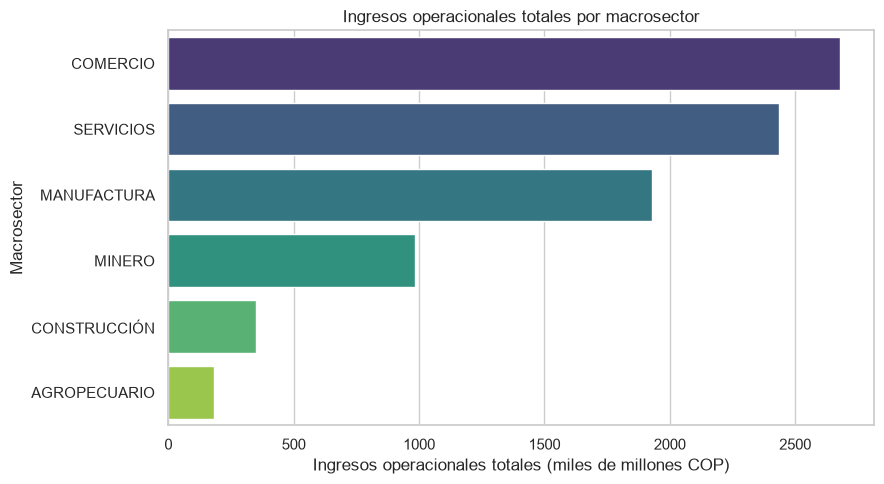

In [164]:
plt.figure()
sns.barplot(x=ingresos_macrosector.values, y=ingresos_macrosector.index, hue=ingresos_macrosector.index, palette="viridis", legend=False)
plt.title("Ingresos operacionales totales por macrosector")
plt.xlabel("Ingresos operacionales totales (miles de millones COP)")
plt.ylabel("Macrosector")
plt.tight_layout()
plt.show()

### Pregunta 2: ingresos por región
Hago lo mismo que con el macrosector, pero agrupando por región. Así comparo qué zona del país concentra más ingresos de las empresas grandes.

In [165]:
ingresos_region = df.groupby("REGIÓN")["INGRESOS OPERACIONALES"].sum().sort_values(ascending=False)
ingresos_region

REGIÓN
BOGOTÁ - CUNDINAMARCA    4959.94
ANTIOQUIA                1428.30
COSTA PACÍFICA            703.31
COSTA ATLÁNTICA           669.89
CENTRO - ORIENTE          272.63
EJE CAFETERO              198.74
REGIÓN CARIBE             195.67
OTROS                      94.27
CENTRO - SUR               24.50
LLANOS                     12.36
Name: INGRESOS OPERACIONALES, dtype: float64

Uso barras horizontales ordenadas, igual que en el gráfico anterior, para poder comparar las regiones de un vistazo.

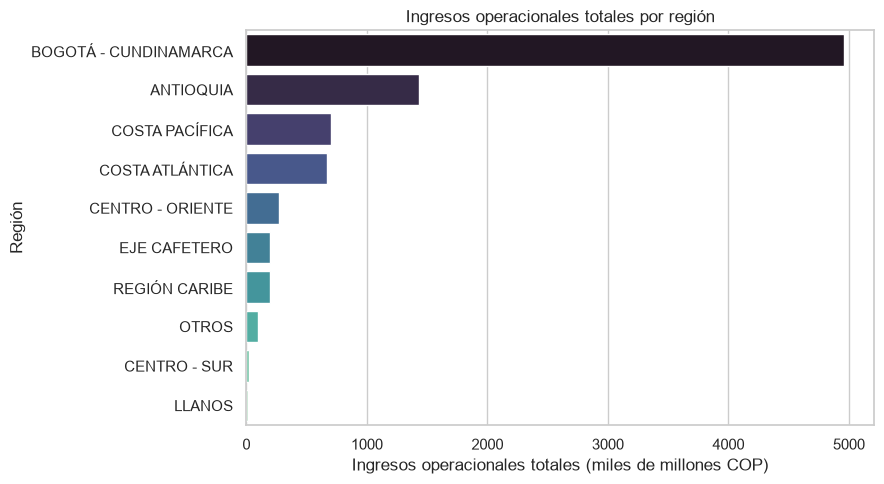

In [166]:
plt.figure()
sns.barplot(x=ingresos_region.values, y=ingresos_region.index, hue=ingresos_region.index, palette="mako", legend=False)
plt.title("Ingresos operacionales totales por región")
plt.xlabel("Ingresos operacionales totales (miles de millones COP)")
plt.ylabel("Región")
plt.tight_layout()
plt.show()

### Pregunta 3: cantidad de empresas por macrosector
Aquí no sumo dinero, solo cuento cuántos registros hay en cada macrosector. Como cada fila es una empresa en un año, el conteo incluye los 5 años (2021 a 2025).

In [167]:
empresas_macrosector = df["MACROSECTOR"].value_counts()
empresas_macrosector

MACROSECTOR
COMERCIO        17335
SERVICIOS       15689
MANUFACTURA     10033
CONSTRUCCIÓN     3854
AGROPECUARIO     2142
MINERO            947
Name: count, dtype: int64

Uso barras horizontales para comparar cuántas empresas tiene cada macrosector. Después comparo este gráfico con el de ingresos para ver si los sectores con más empresas son también los que más venden.

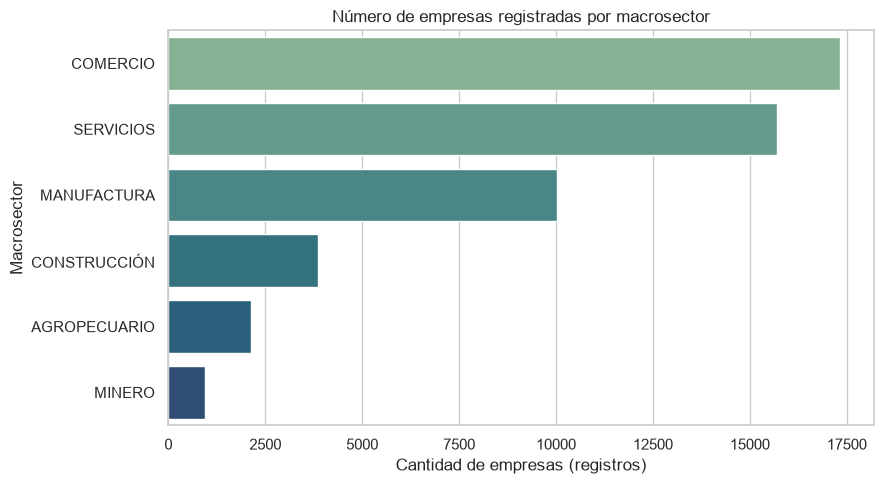

In [168]:
plt.figure()
sns.barplot(x=empresas_macrosector.values, y=empresas_macrosector.index, hue=empresas_macrosector.index, palette="crest", legend=False)
plt.title("Número de empresas registradas por macrosector")
plt.xlabel("Cantidad de empresas (registros)")
plt.ylabel("Macrosector")
plt.tight_layout()
plt.show()

### Limpieza 3: demás columnas de dinero
Aplico la misma limpieza a ganancia, activos, pasivos y patrimonio. Las necesito como números para calcular la matriz de correlación y comparar qué tan relacionadas están entre sí.

In [169]:
otras_cols = ["GANANCIA (PÉRDIDA)", "TOTAL ACTIVOS", "TOTAL PASIVOS", "TOTAL PATRIMONIO"]

for col in otras_cols:
    df[col] = (
        df[col]
        .str.replace("$", "", regex=False)
        .str.replace(" ", "", regex=False)
        .astype(float)
    )

df[otras_cols].describe()

,GANANCIA (PÉRDIDA),TOTAL ACTIVOS,TOTAL PASIVOS,TOTAL PATRIMONIO
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.013162,0.225658,0.116083,0.109319
std,0.237976,2.416679,1.416051,1.121283
min,-3.210000,0.000000,0.000000,-3.690000
25%,0.000000,0.020000,0.010000,0.010000
50%,0.000000,0.040000,0.020000,0.010000
75%,0.010000,0.090000,0.050000,0.040000
max,33.410000,216.850000,130.540000,91.030000


### Pregunta 4: relación entre activos, ingresos y patrimonio
La correlación es un número entre -1 y 1 que dice qué tan juntas se mueven dos variables. Cerca de 1 significa que cuando una sube, la otra también. Cerca de 0 significa que no tienen relación. Uso un heatmap (mapa de calor) porque muestra todas las combinaciones en una sola imagen con colores.

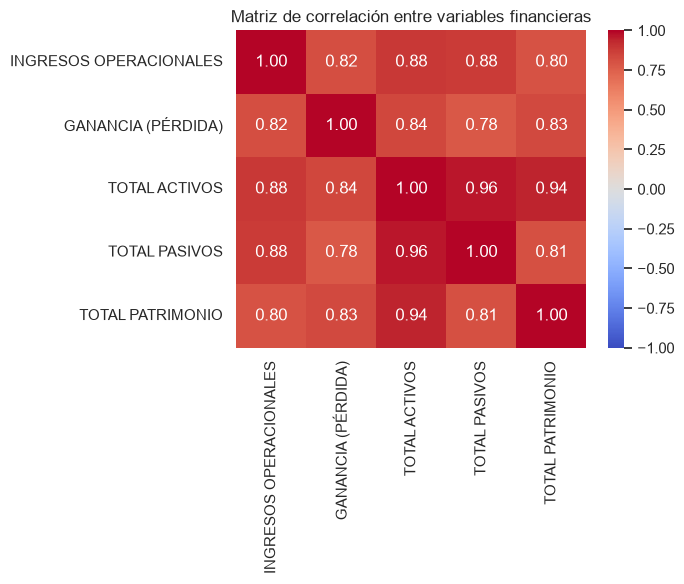

In [170]:
num_cols = ["INGRESOS OPERACIONALES", "GANANCIA (PÉRDIDA)", "TOTAL ACTIVOS", "TOTAL PASIVOS", "TOTAL PATRIMONIO"]
corr = df[num_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación entre variables financieras")
plt.tight_layout()
plt.show()

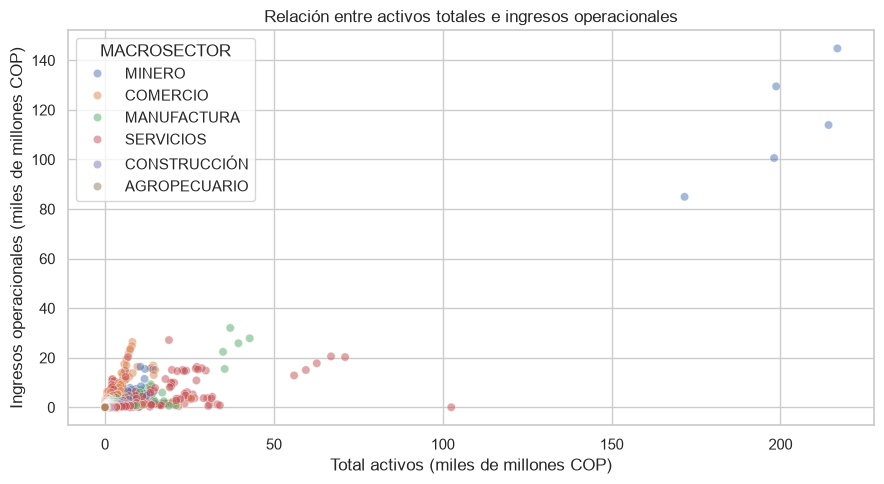

In [171]:
plt.figure()
sns.scatterplot(data=df, x="TOTAL ACTIVOS", y="INGRESOS OPERACIONALES", hue="MACROSECTOR", alpha=0.5)
plt.title("Relación entre activos totales e ingresos operacionales")
plt.xlabel("Total activos (miles de millones COP)")
plt.ylabel("Ingresos operacionales (miles de millones COP)")
plt.tight_layout()
plt.show()

## Respuesta a las preguntas de investigación

**1. ¿Qué macrosector económico concentra mayores ingresos operacionales?**
El macrosector COMERCIO produce el mayor ingreso operativo acumulado (2021-2025), inmediatamente seguido por SERVICIOS y después por MANUFACTURA. El MINERO, CONSTRUCCIÓN y AGROPECUARIO, en cambio, quedan muy por debajo, a pesar de que el MINERO incorpora hasta la mayor empresa individual del país (Ecopetrol).

**2. ¿Qué región concentra los mayores ingresos operacionales?**
La región de BOGOTÁ - CUNDINAMARCA acapara, con mucho margen, los mayores ingresos de las empresas más grandes del país, incluso superando la suma de las otras, además esta es la capital del país; seguidame de ANTIOQUIA la COSTA PACÍFICA y la COSTA ATLÁNTICA ya mucho menores.

**3. ¿Qué macrosectores concentran el mayor número de empresas?**
Los macrosectores con más empresas registradas son COMERCIO y SERVICIOS, que juntos representan más de la mitad de todas las empresas del listado, seguidos por MANUFACTURA. Esto coincide con que estos mismos sectores son también los que más ingresos concentran (pregunta 1), lo que sugiere que su peso económico viene tanto de la cantidad de empresas como del tamaño de sus ingresos.

**4. ¿Las empresas con más activos también tienen más ingresos operacionales y más patrimonio?**
Sí, hay una fuerte y positiva correlación. Si nos fijamos en la matriz de correlación, activos e ingresos operativos tienen una correlación de 0.88, activos y patrimonio una correlación de 0.94 (1 implicaría una relación perfecta). En general, las empresas con más activos también venden más y tienen más patrimonio. Pero cuidado con la lectura: un puñado de gigantes (Ecopetrol, entre otros) pesa mucho en este cálculo, y la gran mayoría de las empresas del listado son mucho más pequeñas.